# Entrenamiento de modelos — Torneo

**Proyecto:** House Pricing — House Prices: Advanced Regression Techniques (Kaggle)

**Notebook:** `3.0-ae-entrenamiento-de-modelos.ipynb` (convención Cookiecutter Data Science)

Este notebook entrena 6 modelos de regresión con optimización de hiperparámetros por validación cruzada
y los compara en un torneo sobre el set de validación.

**Decisiones acordadas:**

| Tema | Decisión |
|---|---|
| Validación cruzada | `KFold` k=10, `shuffle=True`, `random_state=42` |
| Optimización | `GridSearchCV`, al menos 3 configuraciones por modelo (39 en total) |
| Métrica para elegir configuración | RMSE sobre `SalePrice_log` (métrica oficial de Kaggle) |
| Modelos | Regresiones: Ridge, Lasso, ElasticNet · Ensambles: RandomForest, HistGradientBoosting · Red neuronal: MLPRegressor |
| Fuga de datos | El pipeline de FE va **dentro** del CV: se reajusta en cada fold solo con los folds de entrenamiento |
| Torneo | En validación: RMSE real (dólares, tras `expm1`) y RMSE normalizado al rango de `SalePrice` en validación |
| Gráficas | Predicho vs real en validación, una por modelo |

## 0. Librerías y configuración

Importa las librerías, agrega la raíz del proyecto al path y carga la lista de features desde
`pipeline_config.yaml`.

In [1]:
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

sys.path.append(str(Path.cwd().parent))

from house_pricing.config import MODELS_DIR, PROCESSED_DATA_DIR, PROJ_ROOT, RAW_DATA_DIR

RANDOM_STATE = 42
N_FOLDS = 10

with open(PROJ_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    MODEL_FEATURES = yaml.safe_load(f)["MODEL_FEATURES"]

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

2026-11-09 21:14:35.663 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\Anderson Elias\OneDrive - Universidad Galileo\8vo. Trimestre\Product Development - B\house_pricing


## 1. Datos sin transformar y mismo split que la ingeniería de características

Para evitar fuga de datos en la validación cruzada no se usa `train_fe.csv`: ese archivo se transformó
con estadísticas (medianas, límites de outliers, escalado) calculadas con todo el train, así que cada
fold de validación ya las habría «visto». En su lugar se parte de `data/raw/train.csv`, se eliminan las
mismas 2 casas anómalas y se reproduce **exactamente** el split 80/20 del notebook 2.0. La celda
verifica que los `Id` de train y validación coincidan con `train_fe.csv` y `val_fe.csv`.

In [2]:
train_raw = pd.read_csv(RAW_DATA_DIR / "train.csv")
anomalous = (train_raw["GrLivArea"] > 4000) & (train_raw["SalePrice"] < 300000)
train_raw = train_raw.loc[~anomalous].reset_index(drop=True)

X = train_raw[MODEL_FEATURES]
y = np.log1p(train_raw["SalePrice"]).rename("SalePrice_log")

X_train, X_val, y_train, y_val, id_train, id_val = train_test_split(
    X, y, train_raw["Id"], test_size=0.2, random_state=RANDOM_STATE
)

train_fe = pd.read_csv(PROCESSED_DATA_DIR / "train_fe.csv")
val_fe = pd.read_csv(PROCESSED_DATA_DIR / "val_fe.csv")
assert id_train.tolist() == train_fe["Id"].tolist(), "El split de train no coincide con el notebook 2.0"
assert id_val.tolist() == val_fe["Id"].tolist(), "El split de validación no coincide con el notebook 2.0"

print(f"X_train: {X_train.shape} | X_val: {X_val.shape}")
print("Split verificado: mismos Id que train_fe.csv y val_fe.csv")

X_train: (1166, 30) | X_val: (292, 30)
Split verificado: mismos Id que train_fe.csv y val_fe.csv


## 2. Pipeline de ingeniería de características sin ajustar

Carga `models/fe_pipeline.joblib` y lo **clona** con `sklearn.base.clone`: el clon conserva la misma
configuración de los 9 pasos (variables, métodos, umbrales) pero sin ningún parámetro aprendido. Así,
dentro del CV, cada fold vuelve a calcular medianas, modas, límites del Winsorizer, Yeo-Johnson y escalado
solo con sus datos de entrenamiento. La celda verifica que, ajustado con todo `X_train`, el clon produce
exactamente `val_fe.csv`.

In [3]:
fe_pipeline = clone(joblib.load(MODELS_DIR / "fe_pipeline.joblib"))

X_val_check = clone(fe_pipeline).fit(X_train).transform(X_val)
assert np.allclose(X_val_check.values, val_fe.drop(columns=["Id", "SalePrice_log"]).values)
print("El pipeline clonado reproduce val_fe.csv")

fe_pipeline

El pipeline clonado reproduce val_fe.csv


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('drop_high_missing', ...), ('categorical_imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_drop,['FireplaceQu']
,imputation_method,'frequent'
,variables,"['Neighborhood', 'ExterQual', ...]"
,fill_value,'Missing'
,return_object,False
,ignore_format,False
,variables,"['GarageYrBlt', 'LotFrontage']"


## 3. Modelos, grillas de hiperparámetros y esquema de validación cruzada

Define el `KFold` (k=10, con shuffle) y los 6 modelos del torneo con sus grillas. Cada modelo se envuelve
en `Pipeline(fe + modelo)`, por eso los hiperparámetros llevan el prefijo `model__`. Las grillas incluyen
opciones de regularización para controlar el sobreajuste: `alpha` en las lineales y en el MLP,
`max_depth`/`min_samples_leaf`/`max_features` en los árboles, y `early_stopping` en el MLP (que separa su
validación interna de los mismos datos de entrenamiento del fold, sin tocar el fold de validación).

In [4]:
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.1, 1, 10, 30, 100]},
    ),
    "Lasso": (
        Lasso(max_iter=50000),
        {"model__alpha": [0.0001, 0.0005, 0.001, 0.005, 0.01]},
    ),
    "ElasticNet": (
        ElasticNet(max_iter=50000),
        {"model__alpha": [0.0005, 0.001, 0.005], "model__l1_ratio": [0.2, 0.5, 0.8]},
    ),
    "RandomForest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        {
            "model__max_depth": [None, 15],
            "model__max_features": [0.33, "sqrt"],
            "model__min_samples_leaf": [1, 3],
        },
    ),
    "HistGradientBoosting": (
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "model__learning_rate": [0.03, 0.1],
            "model__max_iter": [300, 600],
            "model__max_depth": [3, None],
        },
    ),
    "MLP": (
        MLPRegressor(early_stopping=True, max_iter=2000, random_state=RANDOM_STATE),
        {"model__hidden_layer_sizes": [(64,), (128, 64)], "model__alpha": [0.001, 0.1]},
    ),
}

grid_summary = pd.DataFrame({
    "modelo": list(models),
    "configuraciones": [int(np.prod([len(v) for v in grid.values()])) for _, grid in models.values()],
})
print(f"Total de configuraciones: {grid_summary['configuraciones'].sum()} x {N_FOLDS} folds")
grid_summary

Total de configuraciones: 39 x 10 folds


,modelo,configuraciones
0,Ridge,5
1,Lasso,5
2,ElasticNet,9
3,RandomForest,8
4,HistGradientBoosting,8
5,MLP,4


## 4. Entrenamiento con GridSearchCV

Para cada modelo, `GridSearchCV` prueba todas las configuraciones de su grilla con KFold k=10 sobre
`X_train` y elige la de menor RMSE en escala log. Después reentrena la mejor configuración con todo
`X_train` (`refit=True`). El set de validación **no** participa en ningún momento.

In [5]:
searches = {}

for name, (model, grid) in models.items():
    start = time.perf_counter()
    search = GridSearchCV(
        estimator=Pipeline([("fe", clone(fe_pipeline)), ("model", model)]),
        param_grid=grid,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        return_train_score=True,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name:22s} RMSE CV (log): {-search.best_score_:.4f} | {time.perf_counter() - start:5.1f}s | {search.best_params_}")

Ridge                  RMSE CV (log): 0.1287 |  52.5s | {'model__alpha': 1}


Lasso                  RMSE CV (log): 0.1287 |  34.5s | {'model__alpha': 0.0001}


ElasticNet             RMSE CV (log): 0.1287 |  63.1s | {'model__alpha': 0.0005, 'model__l1_ratio': 0.2}


RandomForest           RMSE CV (log): 0.1378 |  95.5s | {'model__max_depth': 15, 'model__max_features': 0.33, 'model__min_samples_leaf': 1}


HistGradientBoosting   RMSE CV (log): 0.1348 |  91.0s | {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__max_iter': 600}


MLP                    RMSE CV (log): 0.2829 |  77.9s | {'model__alpha': 0.1, 'model__hidden_layer_sizes': (64,)}


## 5. Resultados de la validación cruzada

Resume, para la mejor configuración de cada modelo, el RMSE promedio (escala log) en los folds de
entrenamiento y de validación del CV, y su desviación entre folds. Una brecha grande entre
`rmse_train_log` y `rmse_cv_log` indica sobreajuste.

In [6]:
cv_rows = []
for name, search in searches.items():
    results, best = search.cv_results_, search.best_index_
    cv_rows.append({
        "modelo": name,
        "rmse_train_log": -results["mean_train_score"][best],
        "rmse_cv_log": -results["mean_test_score"][best],
        "std_cv_log": results["std_test_score"][best],
        "mejores_hiperparametros": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
    })

cv_df = pd.DataFrame(cv_rows).sort_values("rmse_cv_log").reset_index(drop=True)
cv_df.round(4)

,modelo,rmse_train_log,rmse_cv_log,std_cv_log,mejores_hiperparametros
0,Ridge,0.1216,0.1287,0.0144,{'alpha': 1}
1,ElasticNet,0.1217,0.1287,0.0142,"{'alpha': 0.0005, 'l1_ratio': 0.2}"
2,Lasso,0.1217,0.1287,0.0143,{'alpha': 0.0001}
3,HistGradientBoosting,0.0915,0.1348,0.0179,"{'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 600}"
4,RandomForest,0.0523,0.1378,0.0181,"{'max_depth': 15, 'max_features': 0.33, 'min_samples_leaf': 1}"
5,MLP,0.1504,0.2829,0.0333,"{'alpha': 0.1, 'hidden_layer_sizes': (64,)}"


## 6. Torneo en el set de validación

Cada modelo (mejor configuración, reentrenada con todo `X_train`) predice el set de validación. Como el
target está en escala log, las predicciones se revierten con `np.expm1` para medir en dólares:

- **`rmse_real`**: RMSE en dólares entre el `SalePrice` real y el predicho.
- **`nrmse_rango`**: `rmse_real / (máx − mín de SalePrice en validación)`. Expresa el error como fracción
  del rango de precios; por ejemplo, 0.05 = un error típico del 5% del rango.
- **`rmse_val_log`**: RMSE en escala log, comparable con `rmse_cv_log`. Si el de validación es mucho
  peor que el de CV, el modelo no generaliza.

El ganador es el de menor `rmse_real`.

In [7]:
y_val_real = np.expm1(y_val)
val_range = y_val_real.max() - y_val_real.min()

predictions = {}
val_rows = []
for name, search in searches.items():
    pred_log = search.predict(X_val)
    predictions[name] = np.expm1(pred_log)
    rmse_real = root_mean_squared_error(y_val_real, predictions[name])
    val_rows.append({
        "modelo": name,
        "rmse_real": rmse_real,
        "nrmse_rango": rmse_real / val_range,
        "rmse_val_log": root_mean_squared_error(y_val, pred_log),
    })

tournament = (
    pd.DataFrame(val_rows)
    .merge(cv_df[["modelo", "rmse_train_log", "rmse_cv_log"]], on="modelo")
    .sort_values("rmse_real")
    .reset_index(drop=True)
)
tournament.index = tournament.index + 1
tournament.index.name = "posición"

print(f"Rango de SalePrice en validación: {y_val_real.min():,.0f} – {y_val_real.max():,.0f} (= {val_range:,.0f})")
print(f"Ganador: {tournament.iloc[0]['modelo']} (RMSE real = {tournament.iloc[0]['rmse_real']:,.0f})")
tournament.style.format({
    "rmse_real": "{:,.0f}", "nrmse_rango": "{:.4f}", "rmse_val_log": "{:.4f}",
    "rmse_train_log": "{:.4f}", "rmse_cv_log": "{:.4f}",
})

Rango de SalePrice en validación: 35,311 – 451,950 (= 416,639)
Ganador: ElasticNet (RMSE real = 22,363)


,modelo,rmse_real,nrmse_rango,rmse_val_log,rmse_train_log,rmse_cv_log
posición,,,,,,
1,ElasticNet,"22,363",0.0537,0.1332,0.1217,0.1287
2,Lasso,"22,371",0.0537,0.1332,0.1217,0.1287
3,Ridge,"22,469",0.0539,0.1335,0.1216,0.1287
4,HistGradientBoosting,"23,423",0.0562,0.1403,0.0915,0.1348
5,RandomForest,"23,920",0.0574,0.1476,0.0523,0.1378
6,MLP,"101,113",0.2427,0.3007,0.1504,0.2829


## 7. Gráficas de desempeño: predicho vs real en validación

Genera en un ciclo un scatter por modelo (ordenados según el torneo) con el `SalePrice` real en el eje x
y el predicho en el eje y, ambos en dólares. La línea punteada es la predicción perfecta (y = x): cuanto
más pegados estén los puntos a ella, mejor el modelo. El título muestra el RMSE real y el RMSE
normalizado al rango. Los ejes se fijan al rango de precios reales; si un modelo predice valores fuera
de ese rango, el título indica cuántos puntos quedan fuera del eje.

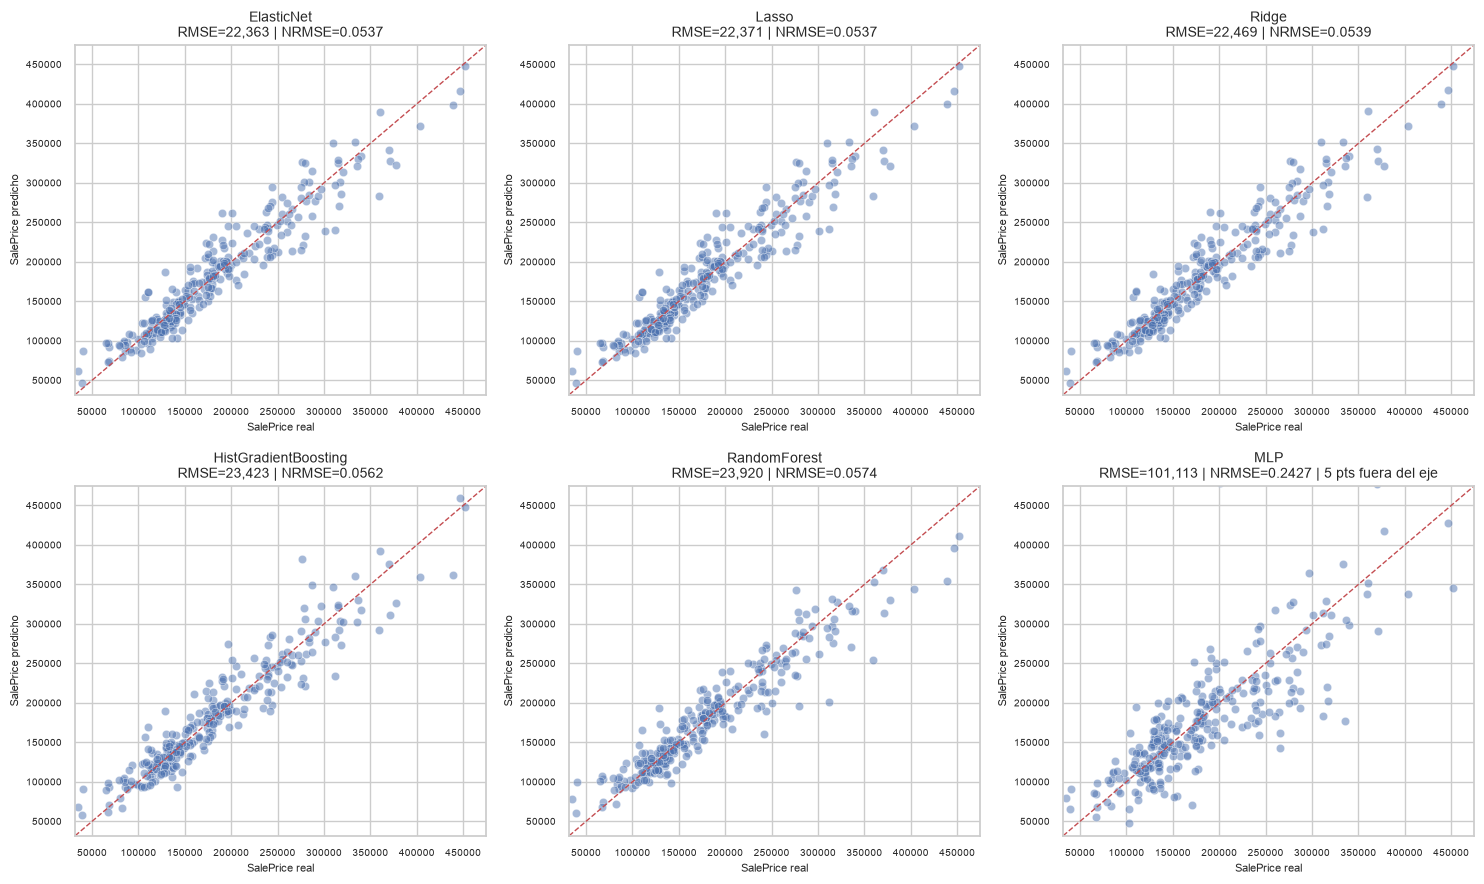

In [8]:
n_cols = 3
n_models = len(tournament)
n_rows = -(-n_models // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4.5))
axes = axes.flatten()
limits = [y_val_real.min() * 0.9, y_val_real.max() * 1.05]

for ax, (_, row) in zip(axes, tournament.iterrows()):
    pred = predictions[row["modelo"]]
    n_outside = int(((pred < limits[0]) | (pred > limits[1])).sum())
    sns.scatterplot(x=y_val_real, y=pred, ax=ax, alpha=0.5)
    ax.plot(limits, limits, "r--", linewidth=1)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    outside_note = f" | {n_outside} pts fuera del eje" if n_outside else ""
    ax.set_title(
        f"{row['modelo']}\nRMSE={row['rmse_real']:,.0f} | NRMSE={row['nrmse_rango']:.4f}{outside_note}", fontsize=10
    )
    ax.set_xlabel("SalePrice real", fontsize=8)
    ax.set_ylabel("SalePrice predicho", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Guardado del modelo ganador

Construye el **pipeline resultado** con la configuración del ganador del torneo y lo guarda en
`models/best_model.joblib`. El pipeline recibe los datos **crudos** (todas las columnas de `train.csv` o
`test.csv`) y devuelve el precio en **dólares**:

1. `select`: `ColumnTransformer` que conserva solo las 30 `MODEL_FEATURES` y descarta el resto.
2. `fe`: pipeline completo de ingeniería de características (los 9 pasos del notebook 2.0).
3. `model`: el modelo ganador con sus mejores hiperparámetros.
4. Todo envuelto en `TransformedTargetRegressor`: entrena con `log1p(SalePrice)` y al predecir aplica
   `expm1` automáticamente.

Por decisión del proyecto se **reentrena con train + validación** (1458 casas, sin las 2 anómalas). Por
eso el RMSE del torneo es la referencia de desempeño de esta configuración, pero ya no hay un set
reservado que mida este modelo final.

In [9]:
winner = tournament.iloc[0]["modelo"]
winner_model = clone(searches[winner].best_estimator_.named_steps["model"])

feature_selector = ColumnTransformer(
    [("select", "passthrough", MODEL_FEATURES)], remainder="drop", verbose_feature_names_out=False
).set_output(transform="pandas")

best_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("select", feature_selector),
        ("fe", clone(fe_pipeline)),
        ("model", winner_model),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)

X_full = train_raw.drop(columns=["SalePrice"])
y_full = train_raw["SalePrice"]
best_model.fit(X_full, y_full)

joblib.dump(best_model, MODELS_DIR / "best_model.joblib")

print(f"Ganador: {winner} | hiperparámetros: {winner_model.get_params()}")
print(f"Entrenado con {X_full.shape[0]} casas y {X_full.shape[1]} columnas crudas")
print(f"Guardado en {MODELS_DIR / 'best_model.joblib'}")
best_model

Ganador: ElasticNet | hiperparámetros: {'alpha': 0.0005, 'copy_X': True, 'fit_intercept': True, 'l1_ratio': 0.2, 'max_iter': 50000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
Entrenado con 1458 casas y 80 columnas crudas
Guardado en C:\Users\Anderson Elias\OneDrive - Universidad Galileo\8vo. Trimestre\Product Development - B\house_pricing\models\best_model.joblib


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...iter=50000))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,80
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...iter=50000))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('fe', ...), ...]"
